# Lab 1

### Setup
Load the libraries and set the random seed.

In [11]:
%pip install numpy pandas matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


### Import the data

In [12]:
import numpy as np
import seaborn as sns

df = sns.load_dataset('penguins')

print(df.head())

# Remove NaNs
df = df.dropna()

# Remove outliers
threshold = 1.5
for col in df.select_dtypes(include=[np.number]).columns:
        mean = df[col].mean()
        std = df[col].std()
        
        # Calculate z-scores
        z_scores = np.abs((df[col] - mean) / std)
        
        # Count outliers
        outliers = (z_scores > threshold).sum()
        
        # Remove outliers
        df = df[z_scores <= threshold]

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  


### Define normality tests
We will use histograms, Q-Q plots and the Kolmogorov-Smirnov test

In [13]:
import matplotlib.pyplot as plt
from scipy.stats import probplot, kstest


def kstest_with_fit(series):
    mu, sigma = series.mean(), series.std(ddof=0)
    return kstest(series, 'norm', args=(mu, sigma)).pvalue


def normality_tests(df, target_columns):
    print("Plotting histograms for numerical columns...")
    df[target_columns].hist(bins=15, figsize=(10, 5), layout=(1, len(target_columns)))
    plt.suptitle('Histograms of Numerical Columns')
    plt.show()

    print("Plotting Q-Q plots for numerical columns...")
    plt.figure(figsize=(10, 5))
    for i, col in enumerate(target_columns):
        plt.subplot(1, len(target_columns), i + 1)
        probplot(df[col], dist="norm", plot=plt)
        plt.title(f'Q-Q Plot of {col}')
    plt.tight_layout()
    plt.show()

    print(f'Kolmogorov-Smirnov test for normality: '
          f'{[kstest_with_fit(df[col]) for col in target_columns]}')

### Test normality
Test the normality using a few skewed columns

Plotting histograms for numerical columns...


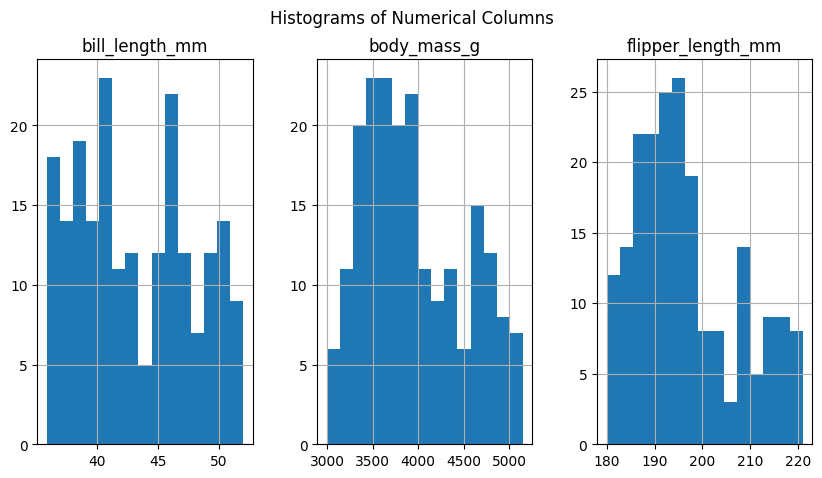

Plotting Q-Q plots for numerical columns...


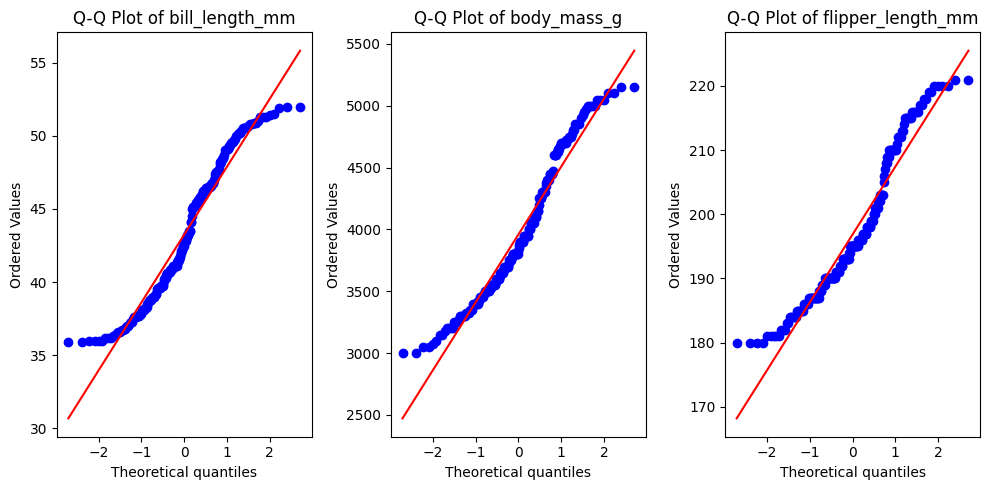

Kolmogorov-Smirnov test for normality: [np.float64(0.016366412394190562), np.float64(0.016556703124303677), np.float64(0.0032776644694928205)]


In [14]:
import numpy as np

# Initial normality tests on skewed columns
target_columns = ['bill_length_mm', 'body_mass_g', 'flipper_length_mm']
normality_tests(df, target_columns)

### Normalize data

Kolmogorov-Smirnov test results before transformation: [0.01636641 0.0165567  0.00327766]
Kolmogorov-Smirnov test results after log transformation: [0.0555576  0.10151344 0.00903504]
Plotting histograms for numerical columns...


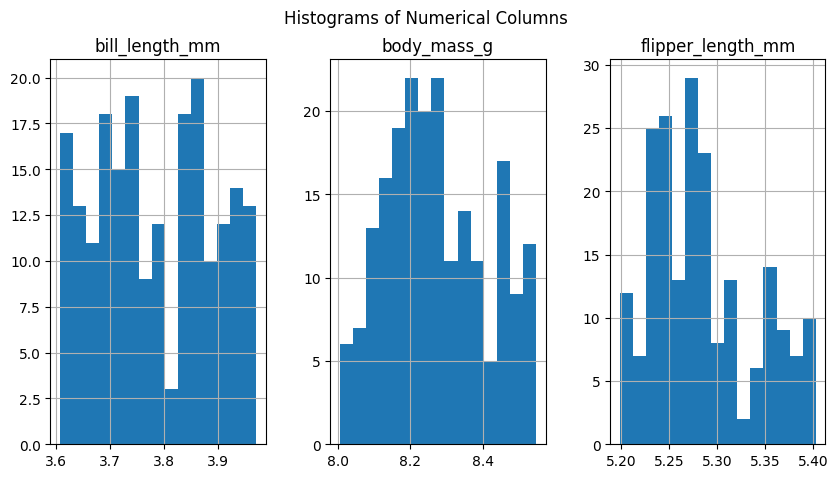

Plotting Q-Q plots for numerical columns...


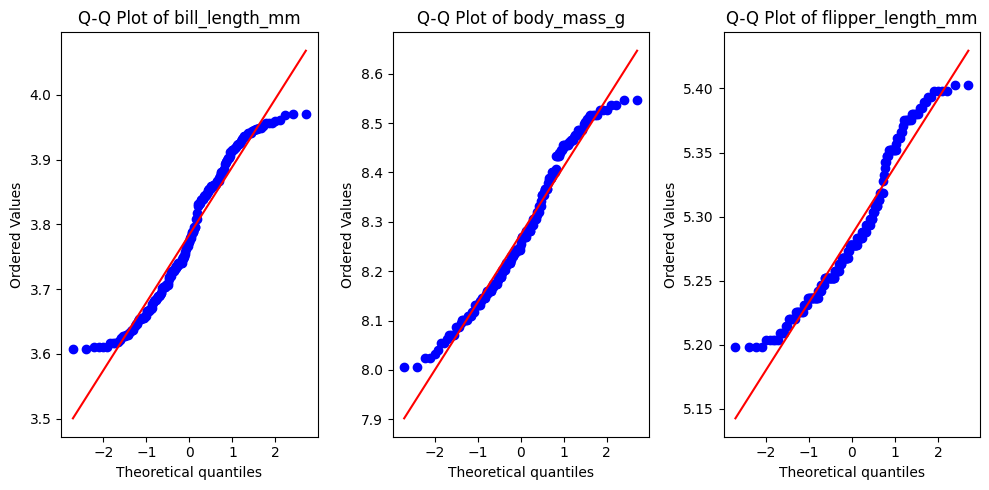

Kolmogorov-Smirnov test for normality: [np.float64(0.055557601004738055), np.float64(0.1015134384182701), np.float64(0.009035036552240203)]


In [15]:
# Derive a new dataframe with log-transformed columns
kolmogorov_smirnov = np.array([kstest_with_fit(df[col]) for col in target_columns])
print(f"Kolmogorov-Smirnov test results before transformation: {kolmogorov_smirnov}")
df_normalized = df.copy()
df_normalized[target_columns] = df_normalized[target_columns].apply(
    lambda x: np.log1p(x)
)
kolmogorov_smirnov = np.array(
    [kstest_with_fit(df_normalized[col]) for col in target_columns]
)
print(f"Kolmogorov-Smirnov test results after log transformation: {kolmogorov_smirnov}")
normality_tests(df_normalized, target_columns)